## 1. Импорты

In [1]:
import os
import json

import torch
from PIL import Image
from IPython.display import display
from torchvision.models import ResNet34_Weights, ResNet50_Weights, resnet34, resnet50

## 2. Инициализация

In [2]:
device = torch.device("cuda")
folder = "data/imagenet_sample"
torch.hub.set_dir("data/torch")

weights34 = ResNet34_Weights.IMAGENET1K_V1
weights50 = ResNet50_Weights.IMAGENET1K_V1
classes = weights34.meta["categories"]

models = {
    "ResNet34": resnet34(weights=weights34).to(device).eval(),
    "ResNet50": resnet50(weights=weights50).to(device).eval(),
}
transforms = {
    "ResNet34": weights34.transforms(),
    "ResNet50": weights50.transforms(),
}

print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 4060 Ti


## 3. Изображения и правильные классы

In [ ]:
image_paths = [
    os.path.join(folder, filename)
    for filename in sorted(os.listdir(folder))
    if filename.lower().endswith((".jpg", ".jpeg"))
]

with open(os.path.join(folder, "manifest.json"), encoding="utf-8") as file:
    samples = json.load(file)

labels = {sample["filename"]: sample["class_id"] for sample in samples}

Найдено изображений: 10


## 4. Функция оценки модели

In [4]:
def run_model(model, image_paths, labels, transform, device):
    if not image_paths:
        raise ValueError("Список изображений пуст")

    model.eval()
    correct = 0
    total_loss = 0
    predictions = {}

    with torch.inference_mode():
        for path in image_paths:
            with Image.open(path) as source:
                image = source.convert("RGB")
            tensor = transform(image).unsqueeze(0).to(device)
            target = torch.tensor([labels[os.path.basename(path)]], device=device)

            output = model(tensor)
            loss = torch.nn.functional.cross_entropy(output, target)
            probabilities = output.softmax(dim=1)[0]
            scores, indices = probabilities.topk(5)

            correct += (output.argmax(dim=1) == target).sum().item()
            total_loss += loss.item()
            predictions[path] = {
                "indices": indices.tolist(),
                "scores": scores.tolist(),
                "cross_entropy": loss.item(),
            }

    return {
        "accuracy": correct / len(image_paths),
        "cross_entropy": total_loss / len(image_paths),
        "predictions": predictions,
    }

## 5. Сравнение моделей

Accuracy — доля правильных top-1 ответов, cross-entropy — средняя ошибка по изображениям. Чем меньше cross-entropy, тем лучше. Сравнение проводится на 10 примерах.

In [5]:
results = {}
print(f"{'Модель':<12} {'Accuracy':>10} {'Cross-entropy':>15}")

for name, model in models.items():
    metrics = run_model(model, image_paths, labels, transforms[name], device)
    results[name] = metrics
    print(f"{name:<12} {metrics['accuracy']:>10.1%} {metrics['cross_entropy']:>15.4f}")

Модель         Accuracy   Cross-entropy
ResNet34          90.0%          0.2848
ResNet50          90.0%          0.2192


## 6. Фотографии и результаты обеих моделей

Используем сохранённые результаты предыдущего запуска.

n01440764_tench.JPEG — правильный класс: tench


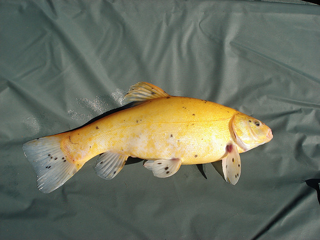

ResNet34: верно, cross-entropy: 0.0458
  tench: 95.5%
  barracouta: 2.0%
  goldfish: 1.6%
  coho: 0.3%
  reel: 0.1%

ResNet50: верно, cross-entropy: 0.0364
  tench: 96.4%
  goldfish: 1.2%
  puffer: 0.9%
  barracouta: 0.7%
  gar: 0.3%

————————————————————————————————————————————————————————————
n01443537_goldfish.JPEG — правильный класс: goldfish


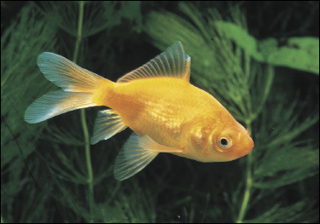

ResNet34: верно, cross-entropy: 0.0081
  goldfish: 99.2%
  tench: 0.8%
  barracouta: 0.0%
  gar: 0.0%
  rock beauty: 0.0%

ResNet50: верно, cross-entropy: 0.2243
  goldfish: 79.9%
  tench: 19.6%
  puffer: 0.2%
  barracouta: 0.1%
  rock beauty: 0.1%

————————————————————————————————————————————————————————————
n01484850_great_white_shark.JPEG — правильный класс: great white shark


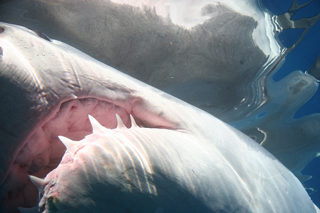

ResNet34: верно, cross-entropy: 0.0616
  great white shark: 94.0%
  tiger shark: 5.4%
  hammerhead: 0.2%
  sturgeon: 0.2%
  dugong: 0.1%

ResNet50: верно, cross-entropy: 0.0822
  great white shark: 92.1%
  tiger shark: 3.9%
  dugong: 2.5%
  hippopotamus: 1.0%
  sturgeon: 0.1%

————————————————————————————————————————————————————————————
n01518878_ostrich.JPEG — правильный класс: ostrich


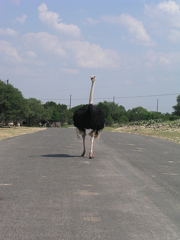

ResNet34: верно, cross-entropy: 0.0061
  ostrich: 99.4%
  water buffalo: 0.1%
  ox: 0.1%
  oxcart: 0.1%
  Arabian camel: 0.0%

ResNet50: верно, cross-entropy: 0.0000
  ostrich: 100.0%
  bustard: 0.0%
  bison: 0.0%
  vulture: 0.0%
  Arabian camel: 0.0%

————————————————————————————————————————————————————————————
n02099601_golden_retriever.JPEG — правильный класс: golden retriever


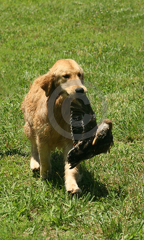

ResNet34: верно, cross-entropy: 0.5618
  golden retriever: 57.0%
  otterhound: 8.5%
  soccer ball: 3.0%
  clumber: 2.9%
  Irish wolfhound: 2.6%

ResNet50: верно, cross-entropy: 0.1200
  golden retriever: 88.7%
  Labrador retriever: 3.0%
  Chesapeake Bay retriever: 1.0%
  cocker spaniel: 0.7%
  curly-coated retriever: 0.6%

————————————————————————————————————————————————————————————
n02123045_tabby.JPEG — правильный класс: tabby


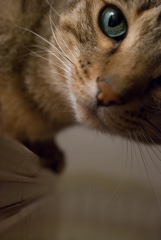

ResNet34: ошибка, cross-entropy: 1.6723
  Egyptian cat: 57.7%
  tiger cat: 22.8%
  tabby: 18.8%
  lynx: 0.3%
  tiger: 0.1%

ResNet50: ошибка, cross-entropy: 1.5852
  Egyptian cat: 48.0%
  tiger cat: 30.9%
  tabby: 20.5%
  lynx: 0.3%
  plastic bag: 0.1%

————————————————————————————————————————————————————————————
n02504458_African_elephant.JPEG — правильный класс: African elephant


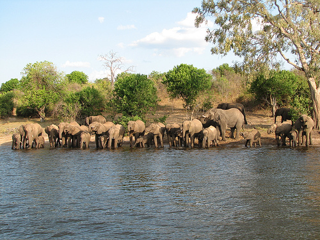

ResNet34: верно, cross-entropy: 0.0404
  African elephant: 96.0%
  Indian elephant: 3.4%
  tusker: 0.5%
  water buffalo: 0.1%
  bison: 0.0%

ResNet50: верно, cross-entropy: 0.0062
  African elephant: 99.4%
  Indian elephant: 0.4%
  tusker: 0.2%
  water buffalo: 0.0%
  sandbar: 0.0%

————————————————————————————————————————————————————————————
n02690373_airliner.JPEG — правильный класс: airliner


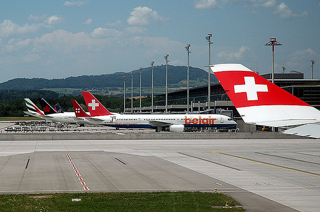

ResNet34: верно, cross-entropy: 0.2390
  airliner: 78.7%
  wing: 19.5%
  ambulance: 0.5%
  warplane: 0.4%
  trimaran: 0.1%

ResNet50: верно, cross-entropy: 0.0934
  airliner: 91.1%
  wing: 8.7%
  warplane: 0.1%
  aircraft carrier: 0.0%
  ambulance: 0.0%

————————————————————————————————————————————————————————————
n07753275_pineapple.JPEG — правильный класс: pineapple


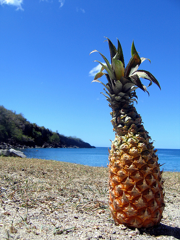

ResNet34: верно, cross-entropy: 0.0014
  pineapple: 99.9%
  ear: 0.1%
  honeycomb: 0.0%
  corn: 0.0%
  banana: 0.0%

ResNet50: верно, cross-entropy: 0.0068
  pineapple: 99.3%
  corn: 0.4%
  ear: 0.2%
  banana: 0.0%
  seashore: 0.0%

————————————————————————————————————————————————————————————
n07753592_banana.JPEG — правильный класс: banana


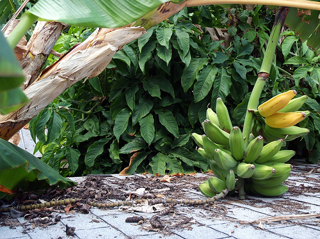

ResNet34: верно, cross-entropy: 0.2116
  banana: 80.9%
  ear: 3.3%
  corn: 3.1%
  pot: 2.4%
  jackfruit: 1.7%

ResNet50: верно, cross-entropy: 0.0373
  banana: 96.3%
  ear: 2.2%
  pineapple: 0.5%
  corn: 0.3%
  artichoke: 0.2%

————————————————————————————————————————————————————————————


In [6]:
for path in image_paths:
    filename = os.path.basename(path)
    target = labels[filename]

    print(f"{filename} — правильный класс: {classes[target]}")
    with Image.open(path) as source:
        image = source.convert("RGB")
    image.thumbnail((320, 240))
    display(image)

    for name in models:
        prediction = results[name]["predictions"][path]
        status = "верно" if prediction["indices"][0] == target else "ошибка"
        print(f"{name}: {status}, cross-entropy: {prediction['cross_entropy']:.4f}")

        for score, index in zip(prediction["scores"], prediction["indices"]):
            print(f"  {classes[index]}: {score:.1%}")
        print()

    print("—" * 60)